--- TRAFFIC METRICS SUMMARY ---
Total Sessions: 74,355
Total Unique Users (Est): 12,477
Bounce Rate: 41.62%
Average Session Depth (Events/Session): 3.04



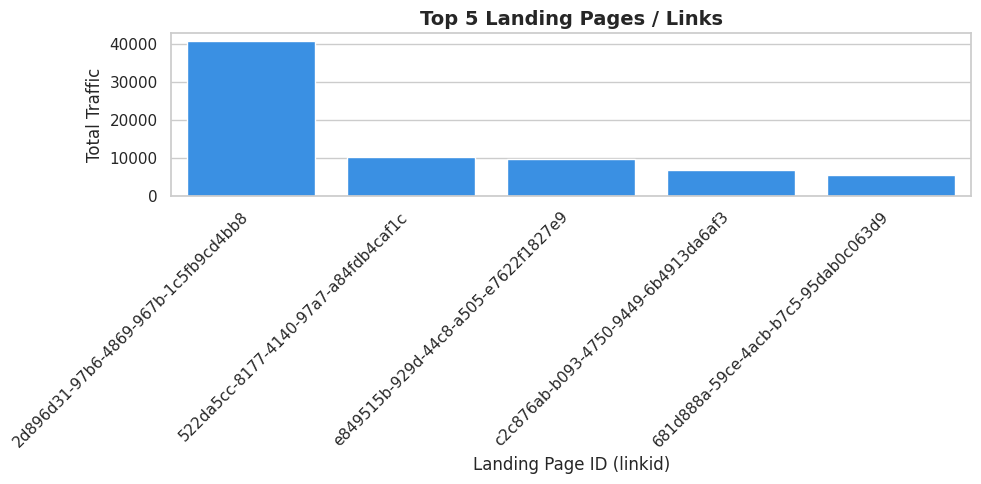

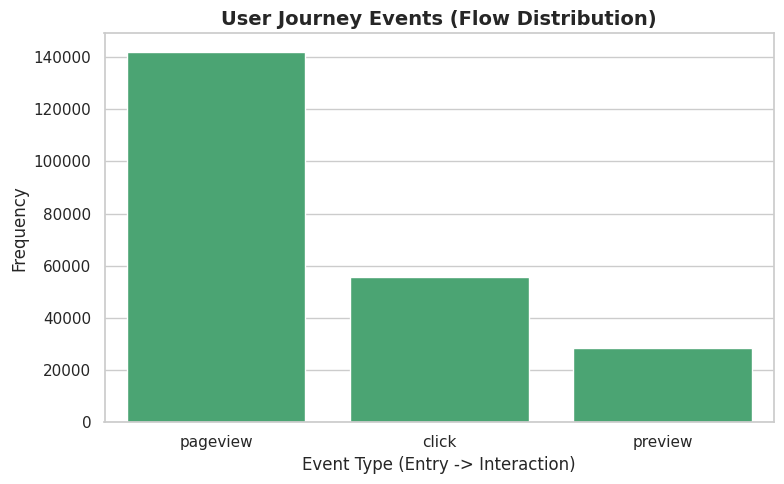

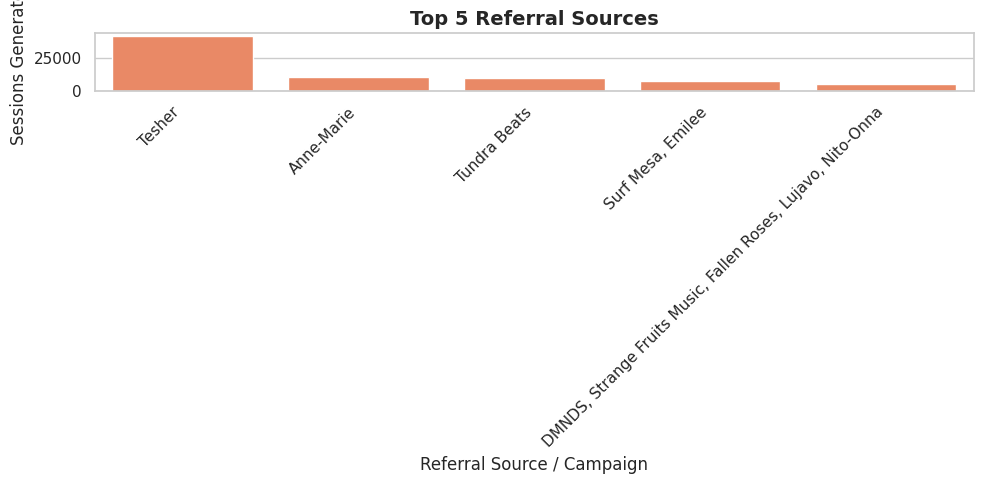

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------
# 1. Parse and clean traffic / log data
# ---------------------------------------------------------
# Load the dataset
df = pd.read_csv('traffic.csv')

# Convert dates and drop rows with critical missing geographic data
df['date'] = pd.to_datetime(df['date'])
df.dropna(subset=['country', 'city'], inplace=True)
df['event'] = df['event'].str.lower()

# ---------------------------------------------------------
# 2. Compute Metrics (Sessions, Users, Bounce Rate, Avg Duration)
# ---------------------------------------------------------
# Session Proxy: Unique date + country + city + linkid combos
sessions = df.groupby(['date', 'country', 'city', 'linkid']).size().reset_index(name='event_count')
total_sessions = len(sessions)

# Users Proxy: Unique geographic footprint profiles
total_users = df.groupby(['country', 'city']).ngroups

# Bounce Rate: Sessions with only 1 event (no further interaction)
bounces = sessions[sessions['event_count'] == 1]
bounce_rate = (len(bounces) / total_sessions) * 100

# Average Session Duration: (Using event depth as a proxy since time-logs are missing)
avg_session_depth = sessions['event_count'].mean()

print("--- TRAFFIC METRICS SUMMARY ---")
print(f"Total Sessions: {total_sessions:,}")
print(f"Total Unique Users (Est): {total_users:,}")
print(f"Bounce Rate: {bounce_rate:.2f}%")
print(f"Average Session Depth (Events/Session): {avg_session_depth:.2f}\n")

# ---------------------------------------------------------
# 3. Visualize user flows and top entry/exit pages
# ---------------------------------------------------------
sns.set_theme(style="whitegrid")

# A. Top 5 Landing Pages (using linkid)
top_pages = df['linkid'].value_counts().head(5)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_pages.index, y=top_pages.values, color="dodgerblue")
plt.title('Top 5 Landing Pages / Links', fontsize=14, fontweight='bold')
plt.xlabel('Landing Page ID (linkid)')
plt.ylabel('Total Traffic')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# B. User Flow (Event Journey Distribution)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='event', order=df['event'].value_counts().index, color="mediumseagreen")
plt.title('User Journey Events (Flow Distribution)', fontsize=14, fontweight='bold')
plt.xlabel('Event Type (Entry -> Interaction)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# C. Referral Sources (Using Artist/Campaign as Proxy)
top_referrals = df['artist'].value_counts().head(5)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_referrals.index, y=top_referrals.values, color="coral")
plt.title('Top 5 Referral Sources', fontsize=14, fontweight='bold')
plt.xlabel('Referral Source / Campaign')
plt.ylabel('Sessions Generated')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()